# Delft3D output for the port of Sisal

This notebook makes all the figures for the Delft3D model of the port of Sisal. If you have the model results as NetCDF (`.nc`) files, you can run it top to bottom to reproduce them.

Delft3D writes two output files:
- the **history file** (`trih-*.nc`): all quantities at a few observation points and cross-sections, at a fine time interval
- the **map file** (`trim-*.nc`): all quantities on the whole grid, at a coarser time interval

Contents:

0. Setup
1. Copying the output files
2. Reading the history file
3. Plotting the history data
4. Reading the map file
5. Plotting the currents
6. Animating the currents
7. Current field at a chosen time
8. Comparing velocities and flow rates across the alternatives
9. Bathymetry of the alternatives
10. Comparing the currents in the channel
11. Location of the stations and cross-sections
12. Fall velocities of the sediment samples

Sections 1-7 look at a single run. Sections 8-11 compare the four alternatives (A-D).

## 0. Setup

In [ ]:
import os
import shutil

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import ListedColormap, TwoSlopeNorm

Paths to the run we want to look at in sections 1-7. Change these to wherever your output is.

In [ ]:
history_file = r'C:\Users\raoul\OneDrive\TU Delft Y5\TU Delft Y5Q1\Delft3D Runs\04 Natural Breakwaters\03 New Design Wide Stable\trih-flow_da_spit_breakwater.nc'
map_file = r'C:\Users\raoul\OneDrive\TU Delft Y5\TU Delft Y5Q1\Delft3D Runs\04 Natural Breakwaters\03 New Design Wide Stable\trim-flow_da_spit_breakwater.nc'

copy_needed = False       # make a fresh copy of the output files (section 1)
animation_needed = False  # make the GIF in section 6 (slow)
cold_start = 6            # spin-up time to skip [hours]

Some small functions that are used throughout the notebook.

A note on the velocities: Delft3D stores `U1` and `V1` on the cell faces (staggered grid), while `XZ` and `YZ` are the cell centres. To plot arrows we average the two faces around each cell centre, and then rotate the result from grid directions to east/north using the grid angle `ALFAS`.

In [ ]:
# Zoom windows used in the plots: (xlim, ylim)
ENTRANCE = ((806000, 807000), (2342900, 2343600))
CHANNEL = ((806250, 806500), (2343000, 2343450))


def decode_names(names):
    # Station and cross-section names are stored as padded byte strings
    return [name.decode('utf-8').split(' ')[0] for name in names.values]


def list_variables(ds):
    print(f"{'Variable Name':<15} {'Long Name':<65} {'Units':<15} {'Dimensions':<40}")
    for name, var in ds.variables.items():
        long_name = var.attrs.get('long_name', 'N/A')
        units = var.attrs.get('units', 'N/A')
        print(f"{name:<15}  {long_name:<65} {units:<15} {str(var.dims):<40}")


def read_station(ds, station):
    # Time series at one observation point, without the spin-up
    i = decode_names(ds['NAMST']).index(station)
    start = cold_start - 1
    return {
        'location': (float(ds['XSTAT'].isel(NOSTAT=i).values[0]), float(ds['YSTAT'].isel(NOSTAT=i).values[0])),
        'time': ds['time'].values[start:],
        'wl': ds['ZWL'].isel(NOSTAT=i).values[start:],
        'hs': ds['ZHS'].isel(NOSTAT=i).values[start:],
        'u': ds['ZCURU'].isel(NOSTAT=i).values[start:],
        'v': ds['ZCURV'].isel(NOSTAT=i).values[start:],
    }


def read_flow_rate(ds, cross_section):
    i = decode_names(ds['NAMTRA']).index(cross_section)
    return np.asarray(ds['CTR'].isel(NTRUV=i).values[cold_start - 1:], dtype=float)


def read_cross_section_xy(ds, cross_section):
    i = decode_names(ds['NAMTRA']).index(cross_section)
    xy = ds['XYTRA'].isel(NTRUV=i).values
    return [float(xy[0]), float(xy[2])], [float(xy[1]), float(xy[3])]


def read_grid(ds):
    # Cell centres and bed level (positive up). The outer row/column are dummy cells filled with zeros.
    x = ds['XZ'].values[1:-1, 1:-1]
    y = ds['YZ'].values[1:-1, 1:-1]
    bed = -ds['DP0'].values[1:-1, 1:-1]
    return x, y, bed


def read_currents(ds, it):
    # East and north velocity at the cell centres for time index `it`
    u = ds['U1'].isel(time=it).values[0]
    v = ds['V1'].isel(time=it).values[0]
    u_centre = 0.5 * (u[:-2, 1:-1] + u[1:-1, 1:-1])
    v_centre = 0.5 * (v[1:-1, :-2] + v[1:-1, 1:-1])
    alpha = np.deg2rad(ds['ALFAS'].values[1:-1, 1:-1])
    u_east = u_centre * np.cos(alpha) - v_centre * np.sin(alpha)
    v_north = u_centre * np.sin(alpha) + v_centre * np.cos(alpha)
    return u_east, v_north


def nearest_time_index(ds, time):
    # time as 'YYYY-MM-DD HH:MM'
    times = ds['time'].values.astype('datetime64[m]')
    return int(np.argmin(np.abs(times - np.datetime64(time, 'm'))))


def time_label(t):
    return np.datetime_as_string(t, unit='m').replace('T', ' ')


def quiver(ax, x, y, u, v, step=1, **kwargs):
    # Arrows on every `step`-th grid point
    s = np.s_[::step, ::step]
    return ax.quiver(x[s], y[s], u[s], v[s], **kwargs)


PANEL_TITLES = {
    'A': 'Detailed Currents in the Channel',
    'B': 'Currents around the Port Entrance',
    'C': 'General Flow Field around the Port',
}


def three_panel_figure(x, y, bed, figsize=(10, 8), when=None):
    # A: channel (left, tall), B: port entrance, C: whole model
    fig, axd = plt.subplot_mosaic([['A', 'B'], ['A', 'C']], figsize=figsize, layout='constrained')
    limits = {'A': CHANNEL, 'B': ENTRANCE, 'C': ((x.min(), x.max()), (y.min(), y.max()))}
    for key, ax in axd.items():
        ax.contour(x, y, bed, levels=[0], colors='k', linewidths=1)
        ax.set_title(PANEL_TITLES[key] + (f' ({when})' if when else ''))
        ax.set_xlim(limits[key][0])
        ax.set_ylim(limits[key][1])
        ax.set_xlabel('Easting [m]')
        ax.set_ylabel('Northing [m]')
        ax.set_aspect('equal')
    axd['A'].tick_params(axis='x', labelrotation=45)
    return fig, axd


def channel_axes(ax, x, y, bed, title, linewidth=0.8):
    # Common styling for the channel close-ups in sections 10 and 11
    ax.contour(x, y, bed, levels=[0], colors='k', linewidths=linewidth)
    ax.set_xlim(CHANNEL[0])
    ax.set_ylim(CHANNEL[1])
    ax.set_title(title)
    ax.set_xlabel('Easting [m]')
    ax.set_aspect('equal')
    ax.tick_params(axis='x', labelrotation=45)

## 1. Copying the output files

xarray can clash with Delft3D if the model is still writing to the files, so we work on a copy (`*-bak.nc`). If `copy_needed = False` the copies from an earlier run are used.

In [ ]:
copied_history_file = history_file.replace('.nc', '-bak.nc')
copied_map_file = map_file.replace('.nc', '-bak.nc')

if copy_needed:
    shutil.copy2(history_file, copied_history_file)
    shutil.copy2(map_file, copied_map_file)

## 2. Reading the history file

The cell below lists all variables in the file, in case you need something else.

In [ ]:
ds_his = xr.open_dataset(copied_history_file)
list_variables(ds_his)

Variable Name   Long Name                                                         Units           Dimensions                              
NAMST            Name of monitoring station                                        N/A             ('NOSTAT',)                             
ALFAS            Orientation ksi-axis w.r.t. pos.x-axis at water level point       arc_degrees     ('NOSTAT',)                             
MNTRA            (M1,N1)-(M2,N2) indices of monitoring cross-sections              1               ('NTRUV', 'length_4')                   
XYTRA            (X1,Y1)-(X2,Y2) coordinates of monitoring cross-sections          m               ('NTRUV', 'length_4')                   
NAMTRA           Name of monitoring cross-section                                  N/A             ('NTRUV',)                              
SIG_LYR          Sigma coordinates of layer centres                                1               ('SIG_LYR',)                            
SIG_INTF         Sigm

In [ ]:
stations = ['smooth_entrance']

his_data = {station: read_station(ds_his, station) for station in stations}
station_x, station_y = zip(*(data['location'] for data in his_data.values()))

for station, data in his_data.items():
    print(f"{station}: (x, y) = {data['location']}")

## 3. Plotting the history data

To hide a plot for a station, add `'u'` or `'v'` to `hidden_plots`. For example `{'smooth_entrance': {'v'}}` hides the V-plot for that station.

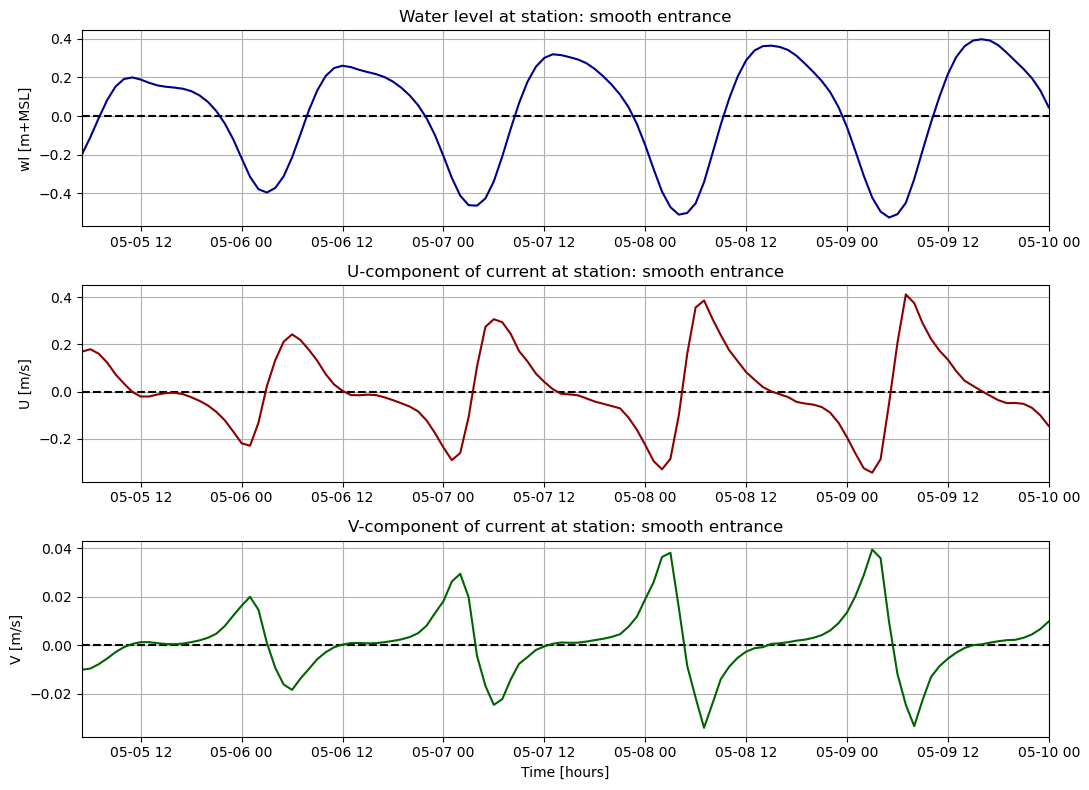

In [ ]:
hidden_plots = {}

panels = [
    ('wl', 'darkblue', 'Water level', 'wl [m+MSL]'),
    ('u', 'darkred', 'U-component of current', 'U [m/s]'),
    ('v', 'darkgreen', 'V-component of current', 'V [m/s]'),
]

for station, data in his_data.items():
    shown = [p for p in panels if p[0] not in hidden_plots.get(station, set())]
    fig, axes = plt.subplots(len(shown), figsize=(11, 8 - 2.5 * (len(panels) - len(shown))), squeeze=False)

    for ax, (key, color, title, ylabel) in zip(axes[:, 0], shown):
        ax.axhline(0, color='k', linestyle='--')
        ax.plot(data['time'], data[key], color)
        ax.set_title(f"{title} at station: {station.replace('_', ' ')}")
        ax.set_ylabel(ylabel)
        ax.set_xlim(data['time'][0], data['time'][-1])
        ax.grid()

    axes[-1, 0].set_xlabel('Time [hours]')
    plt.tight_layout()
    plt.show()

## 4. Reading the map file

In [ ]:
ds_map = xr.open_dataset(copied_map_file)
list_variables(ds_map)

Variable Name   Long Name                                                         Units           Dimensions                              
XCOR             X-coordinate of grid points                                       m               ('MC', 'NC')                            
YCOR             Y-coordinate of grid points                                       m               ('MC', 'NC')                            
XZ               X-coordinate of cell centres                                      m               ('M', 'N')                              
YZ               Y-coordinate of cell centres                                      m               ('M', 'N')                              
ALFAS            Orientation ksi-axis w.r.t. pos.x-axis at water level point       arc_degrees     ('M', 'N')                              
KCU              Mask array for U-velocity points                                  1               ('MC', 'N')                             
KCV              Mask

In [ ]:
map_times = ds_map['time'].values
map_x, map_y, map_bed = read_grid(ds_map)

# Currents at the last time step
u_east, v_north = read_currents(ds_map, -1)

## 5. Plotting the currents

Currents at the end of the simulation, at three zoom levels.

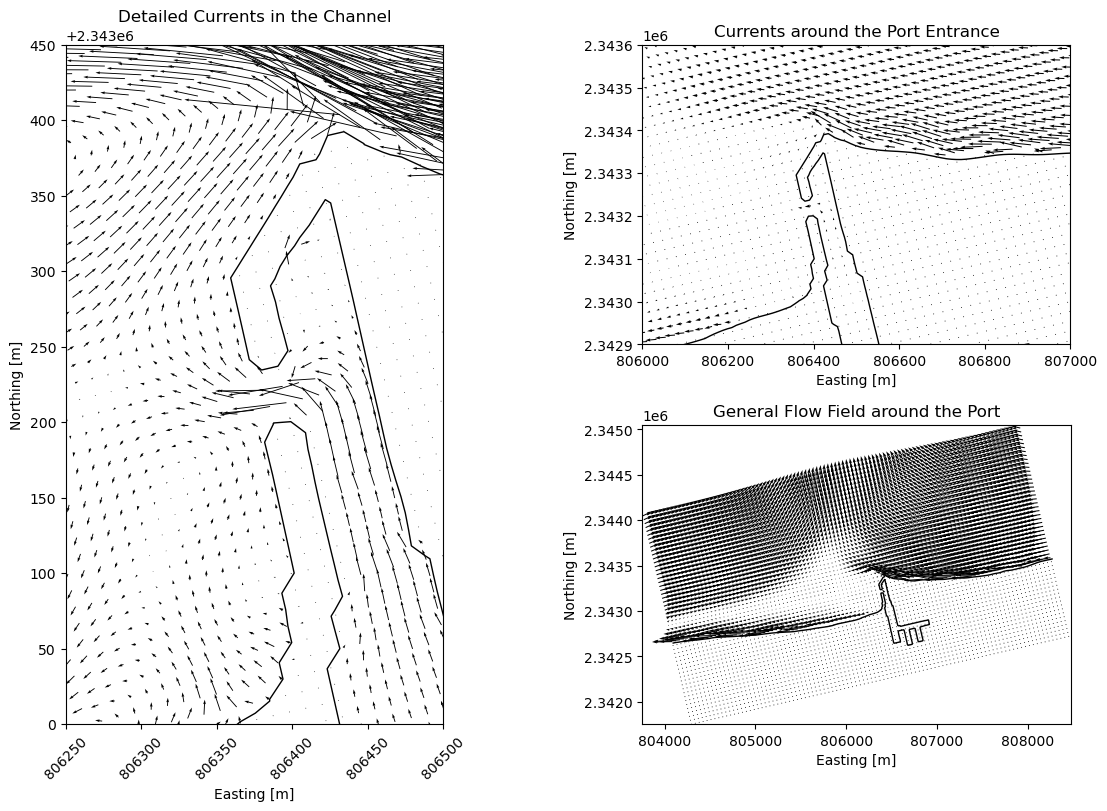

In [ ]:
fig, axd = three_panel_figure(map_x, map_y, map_bed, figsize=(12, 8))

quiver(axd['A'], map_x, map_y, u_east, v_north, step=1, scale=1)
quiver(axd['B'], map_x, map_y, u_east, v_north, step=2, scale=10)
quiver(axd['C'], map_x, map_y, u_east, v_north, step=4, scale=10)
plt.show()

## 6. Animating the currents

Same layout as above, but with the current speed in colour and one frame per map output. Saved as a GIF in `plots/`. Only runs when `animation_needed = True`.

In [ ]:
if animation_needed:
    fig, axd = three_panel_figure(map_x, map_y, map_bed)

    speed = np.hypot(u_east, v_north)
    meshes = [ax.pcolormesh(map_x, map_y, speed, cmap='viridis', vmin=0, vmax=1) for ax in axd.values()]
    arrows_a = quiver(axd['A'], map_x, map_y, u_east, v_north, step=1, scale=1, color='w')
    arrows_b = quiver(axd['B'], map_x, map_y, u_east, v_north, step=4, scale=10, color='w')
    for ax in axd.values():
        ax.scatter(station_x, station_y, color='green', marker='o', zorder=5)

    def update(it):
        u, v = read_currents(ds_map, it)
        for mesh in meshes:
            mesh.set_array(np.hypot(u, v).ravel())
        arrows_a.set_UVC(u, v)
        arrows_b.set_UVC(u[::4, ::4], v[::4, ::4])
        for key, ax in axd.items():
            ax.set_title(f'{PANEL_TITLES[key]} ({time_label(map_times[it])})')

    print('Be patient! This could take up to a minute... or ten...')
    ani = animation.FuncAnimation(fig, update, frames=len(map_times), repeat=False)
    ani.save('plots/currents_animation_test.gif', writer='pillow', fps=10, dpi=120)

## 7. Current field at a chosen time

Set `plot_time` (`YYYY-MM-DD HH:MM`). The closest map output is used.

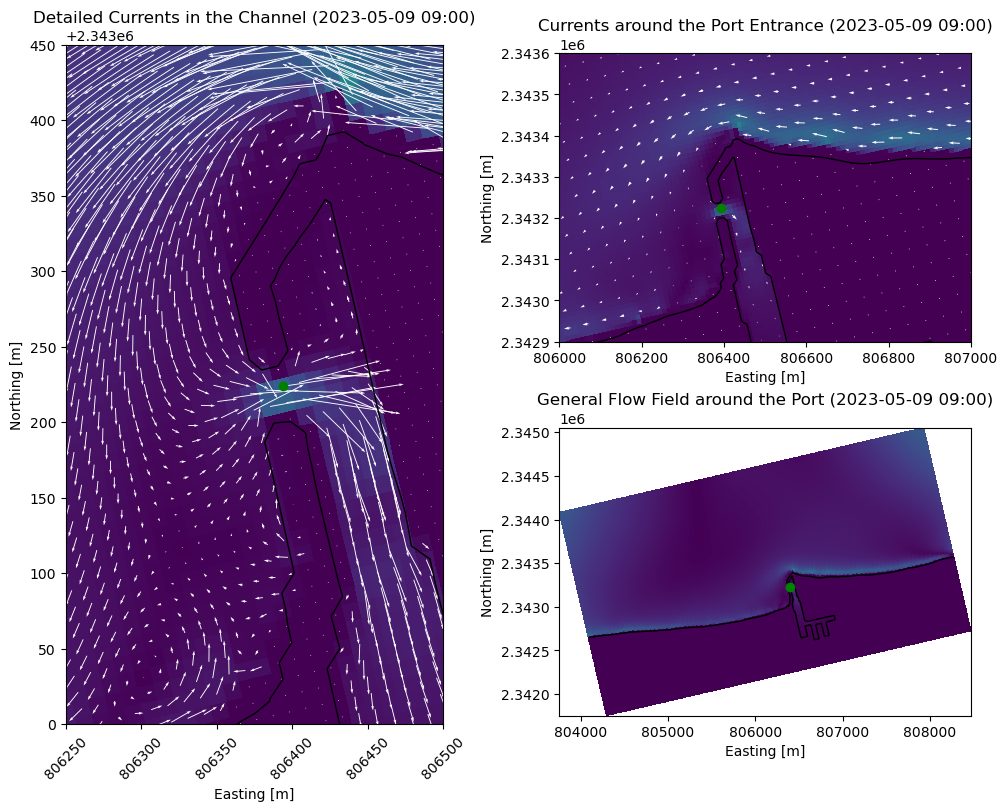

In [ ]:
plot_time = '2023-05-09 09:00'

it = nearest_time_index(ds_map, plot_time)
u, v = read_currents(ds_map, it)

fig, axd = three_panel_figure(map_x, map_y, map_bed, when=time_label(map_times[it]))
for ax in axd.values():
    ax.pcolormesh(map_x, map_y, np.hypot(u, v), cmap='viridis', vmin=0, vmax=1)
    ax.scatter(station_x, station_y, color='green', marker='o', zorder=5)

quiver(axd['A'], map_x, map_y, u, v, step=1, scale=1, color='w')
quiver(axd['B'], map_x, map_y, u, v, step=4, scale=10, color='w')
plt.show()

# 8. Comparing velocities and flow rates across the alternatives

For each alternative we pick one station and one cross-section in the channel. `component` is the velocity component that points along the channel at that station.

In [ ]:
runs_folder = r'C:\Users\raoul\OneDrive\TU Delft Y5\TU Delft Y5Q1\Delft3D Runs'

runs = {
    'constant':  dict(label='A', folder=r'05 Constant Port Depth\02 New', sim='flow_depth_averaged',
                      station='western_jetty_entran', component='v', cross_section='CS_Channel'),
    'base':      dict(label='B', folder=r'02 Test with Depth Averaging', sim='flow_depth_averaged',
                      station='western_jetty_entran', component='v', cross_section='CS_Channel'),
    'extension': dict(label='C', folder=r'03 Extended Breakwaters\02 Depth Averaged Python', sim='flow_extended_breakwaters',
                      station='entry_port', component='v', cross_section='CS_Tweezler'),
    'natural':   dict(label='D', folder=r'04 Natural Breakwaters\01 New Design Wide', sim='flow_da_spit_breakwater',
                      station='smooth_entrance', component='u', cross_section='CS_Smooth'),
}

# The copied (-bak) output files of each run
history_files = {run: os.path.join(runs_folder, r['folder'], f"trih-{r['sim']}-bak.nc") for run, r in runs.items()}
map_files = {run: os.path.join(runs_folder, r['folder'], f"trim-{r['sim']}-bak.nc") for run, r in runs.items()}

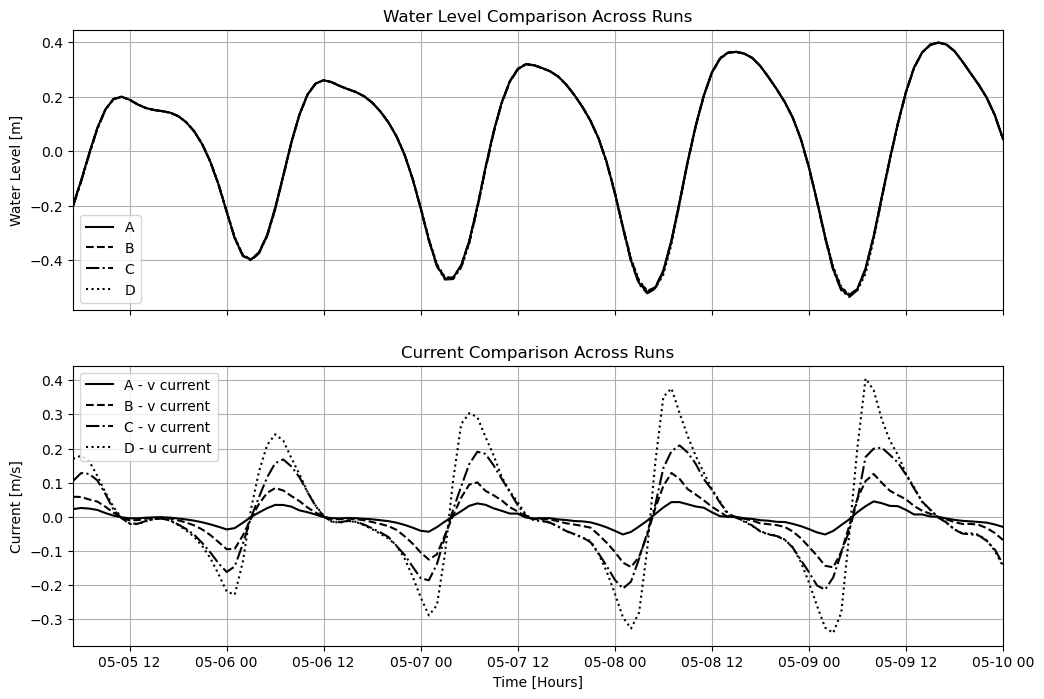

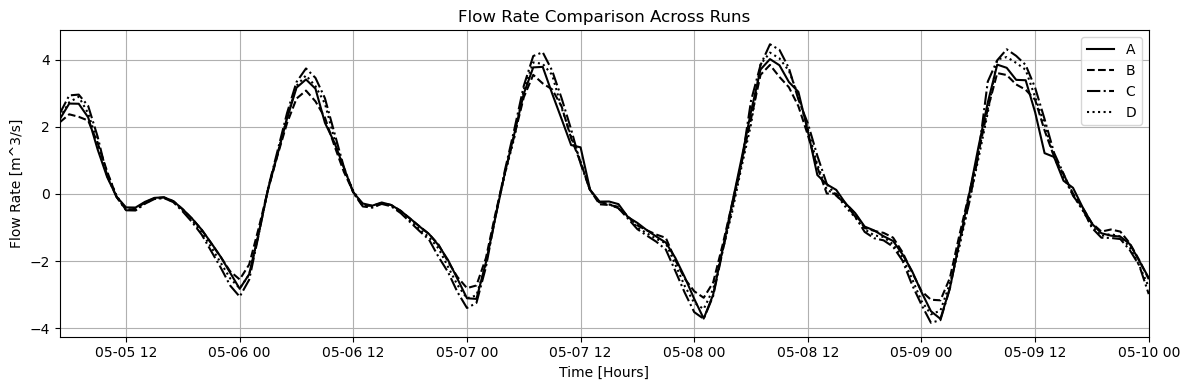

In [ ]:
his_runs = {}
for run, r in runs.items():
    with xr.open_dataset(history_files[run]) as ds:
        his_runs[run] = read_station(ds, r['station'])
        his_runs[run]['flow'] = read_flow_rate(ds, r['cross_section'])
        his_runs[run]['cross_section_xy'] = read_cross_section_xy(ds, r['cross_section'])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
fig_flow, ax3 = plt.subplots(figsize=(12, 4))
styles = ['-', '--', '-.', ':']

for (run, r), style in zip(runs.items(), styles):
    data = his_runs[run]
    # flip v so that all alternatives use the same sign convention
    sign = -1 if r['component'] == 'v' else 1
    ax1.plot(data['time'], data['wl'], 'k', linestyle=style, label=r['label'])
    ax2.plot(data['time'], sign * data[r['component']], 'k', linestyle=style, label=f"{r['label']} - {r['component']} current")
    ax3.plot(data['time'], sign * data['flow'], 'k', linestyle=style, label=r['label'])

time = data['time']  # same for every run
for ax, title, ylabel in [(ax1, 'Water Level Comparison Across Runs', 'Water Level [m]'),
                          (ax2, 'Current Comparison Across Runs', 'Current [m/s]'),
                          (ax3, 'Flow Rate Comparison Across Runs', 'Flow Rate [m^3/s]')]:
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlim(time[0], time[-1])
    ax.legend()
    ax.grid()
ax2.set_xlabel('Time [Hours]')
ax3.set_xlabel('Time [Hours]')

fig.tight_layout()
fig_flow.tight_layout()

### Net flow over a tidal cycle

A tidal cycle runs from one zero-downcrossing of the flow rate (going from positive to negative) to the next. Integrating the flow rate over a full cycle gives the net volume that goes in or out of the port. If the in- and outflow balance, it should be close to zero.

First the last cycle of each run:

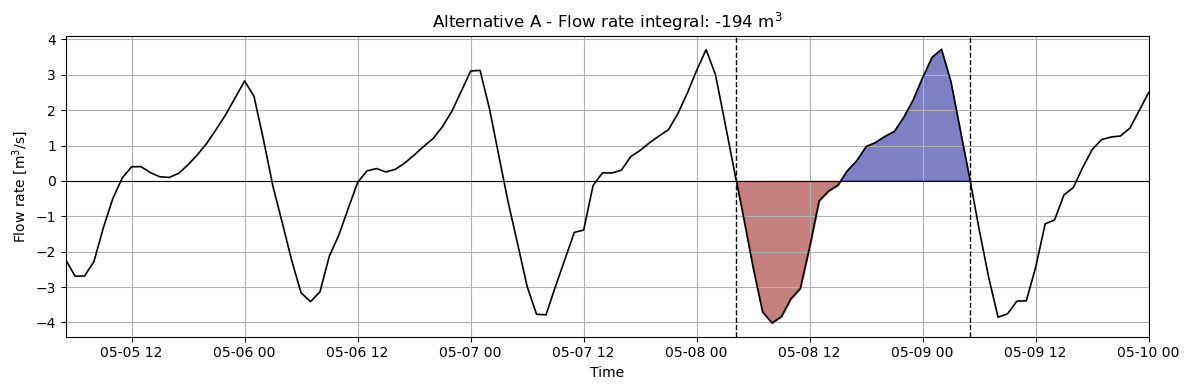

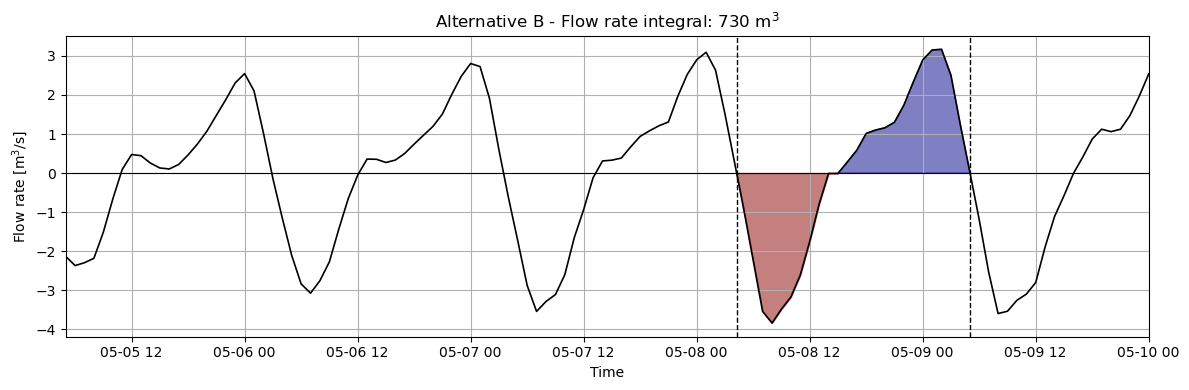

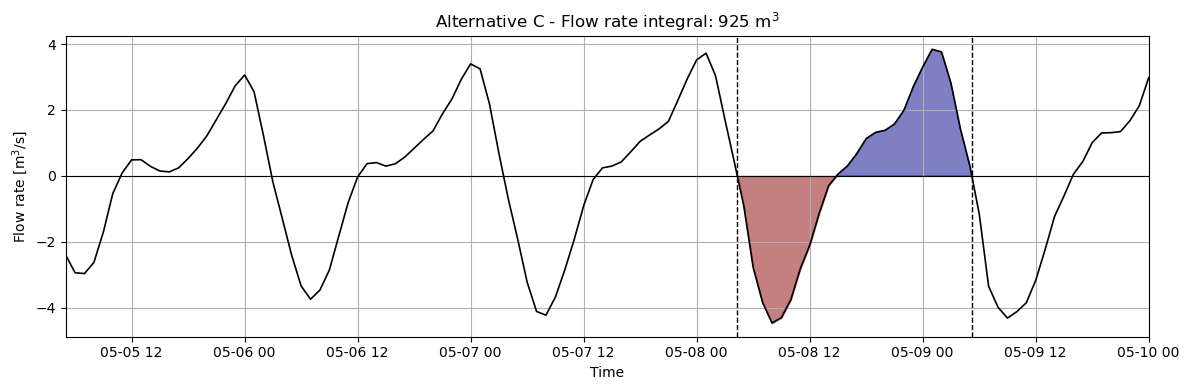

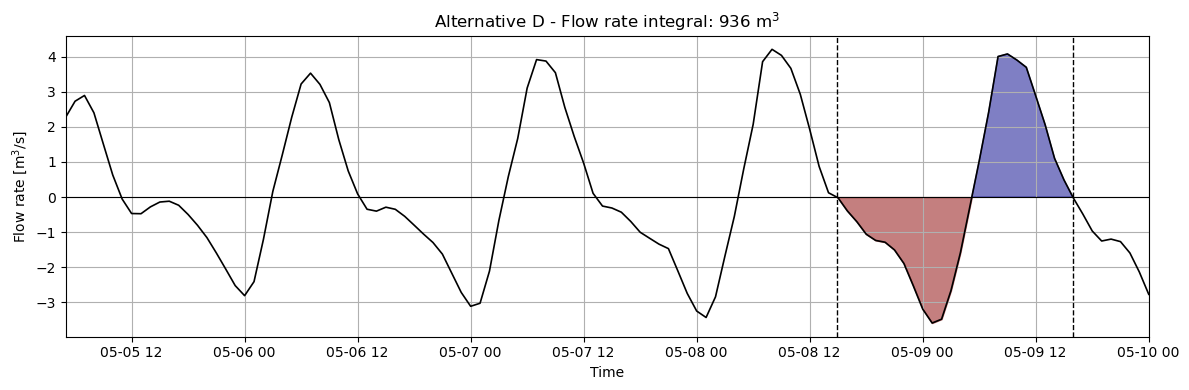

In [ ]:
def seconds_since_start(time):
    seconds = time.astype('datetime64[s]').astype(np.int64)
    return seconds - seconds[0]


def downcrossing_times(t, q):
    # Times where q goes from >= 0 to < 0, linearly interpolated between samples
    ok = np.isfinite(q)
    i = np.flatnonzero(ok[:-1] & ok[1:] & (q[:-1] >= 0) & (q[1:] < 0))
    return t[i] - q[i] * (t[i + 1] - t[i]) / (q[i + 1] - q[i])


def cycle(t, q, t_start, t_end):
    # Samples between two crossings, with q = 0 added at both ends
    inside = (t > t_start) & (t < t_end) & np.isfinite(q)
    return np.r_[t_start, t[inside], t_end], np.r_[0.0, q[inside], 0.0]


for run, r in runs.items():
    time, flow = his_runs[run]['time'], his_runs[run]['flow']
    t = seconds_since_start(time)
    crossings = downcrossing_times(t, flow)
    if len(crossings) < 2:
        raise ValueError(f"Could not find two zero-downcrossings for run '{run}'.")

    t_cycle, q_cycle = cycle(t, flow, crossings[-2], crossings[-1])
    net_volume = np.trapezoid(q_cycle, x=t_cycle)
    dates = time[0] + (t_cycle * 1e9).astype('timedelta64[ns]')

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(time, flow, color='black', linewidth=1.2)
    ax.fill_between(dates, q_cycle, 0, where=q_cycle >= 0, color='darkblue', alpha=0.5, interpolate=True)
    ax.fill_between(dates, q_cycle, 0, where=q_cycle < 0, color='darkred', alpha=0.5, interpolate=True)
    ax.axvline(dates[0], color='black', linestyle='--', linewidth=1.0)
    ax.axvline(dates[-1], color='black', linestyle='--', linewidth=1.0)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f"Alternative {r['label']} - Flow rate integral: {net_volume:.3g} m$^3$")
    ax.set_xlabel('Time')
    ax.set_ylabel('Flow rate [m$^3$/s]')
    ax.set_xlim(time[0], time[-1])
    ax.grid(True)
    fig.tight_layout()
    plt.show()

And the same for every complete cycle, as a table. The last column is the net volume as a percentage of the total volume that passed through the cross-section (in + out).

In [ ]:
rows = []
for run, r in runs.items():
    time, flow = his_runs[run]['time'], his_runs[run]['flow']
    t = seconds_since_start(time)
    crossings = downcrossing_times(t, flow)
    start = time[0].astype('datetime64[s]')

    for n, (t_start, t_end) in enumerate(zip(crossings[:-1], crossings[1:]), start=1):
        t_cycle, q_cycle = cycle(t, flow, t_start, t_end)
        net = np.trapezoid(q_cycle, x=t_cycle)
        total = np.trapezoid(np.abs(q_cycle), x=t_cycle)
        rows.append({
            'Run': r['label'],
            'Interval': n,
            'Start': str(start + np.timedelta64(int(round(t_start)), 's')).replace('T', ' '),
            'End': str(start + np.timedelta64(int(round(t_end)), 's')).replace('T', ' '),
            'Flow-rate integral [m^3]': net,
            'Total displaced volume [m^3]': total,
            'Signed integral [% of total]': abs(100 * net / total) if total else np.nan,
        })

flow_interval_integrals = pd.DataFrame(rows)
display(flow_interval_integrals)

,Run,Interval,Start,End,Flow-rate integral [m^3],Total displaced volume [m^3],Signed integral [% of total]
0,A,1,2023-05-06 02:53:40,2023-05-07 03:31:57,6469.457019,133800.195868,4.835163
1,A,2,2023-05-07 03:31:57,2023-05-08 04:12:47,4345.742454,155261.724720,2.798979
2,A,3,2023-05-08 04:12:47,2023-05-09 05:02:46,-193.916109,173705.289223,0.111635
3,B,1,2023-05-06 02:53:01,2023-05-07 03:29:38,7841.915091,126187.197975,6.214509
4,B,2,2023-05-07 03:29:38,2023-05-08 04:14:29,2613.979347,149050.633724,1.753753
5,B,3,2023-05-08 04:14:29,2023-05-09 05:01:32,729.999312,161196.369422,0.452863
6,C,1,2023-05-06 02:52:25,2023-05-07 03:29:50,7157.090203,149879.446167,4.775231
7,C,2,2023-05-07 03:29:50,2023-05-08 04:18:58,4154.518373,172893.333655,2.402937
8,C,3,2023-05-08 04:18:58,2023-05-09 05:13:00,924.710195,189699.129395,0.487461
9,D,1,2023-05-05 10:55:05,2023-05-06 12:12:28,7024.329134,127814.845246,5.495707


### Maximum and minimum velocity at each station

In [ ]:
rows = {}
for run, r in runs.items():
    time = his_runs[run]['time']
    velocity = his_runs[run][r['component']]
    rows[run] = {
        'Time Max Current': time_label(time[np.argmax(velocity)]),
        'Max Velocity [m/s]': velocity.max(),
        'Time Min Current': time_label(time[np.argmin(velocity)]),
        'Min Velocity [m/s]': velocity.min(),
    }

velostats = pd.DataFrame.from_dict(rows, orient='index')
display(velostats)

,Time Max Current,Max Velocity [m/s],Time Min Current,Min Velocity [m/s]
constant,2023-05-09 02:00,0.05168,2023-05-09 08:00,-0.045123
base,2023-05-09 03:00,0.147876,2023-05-08 07:00,-0.128349
extension,2023-05-09 02:00,0.213176,2023-05-08 08:00,-0.209043
natural,2023-05-09 07:00,0.405034,2023-05-09 03:00,-0.339984


# 9. Bathymetry of the alternatives

The initial bed level of the four port layouts side by side, for the report.

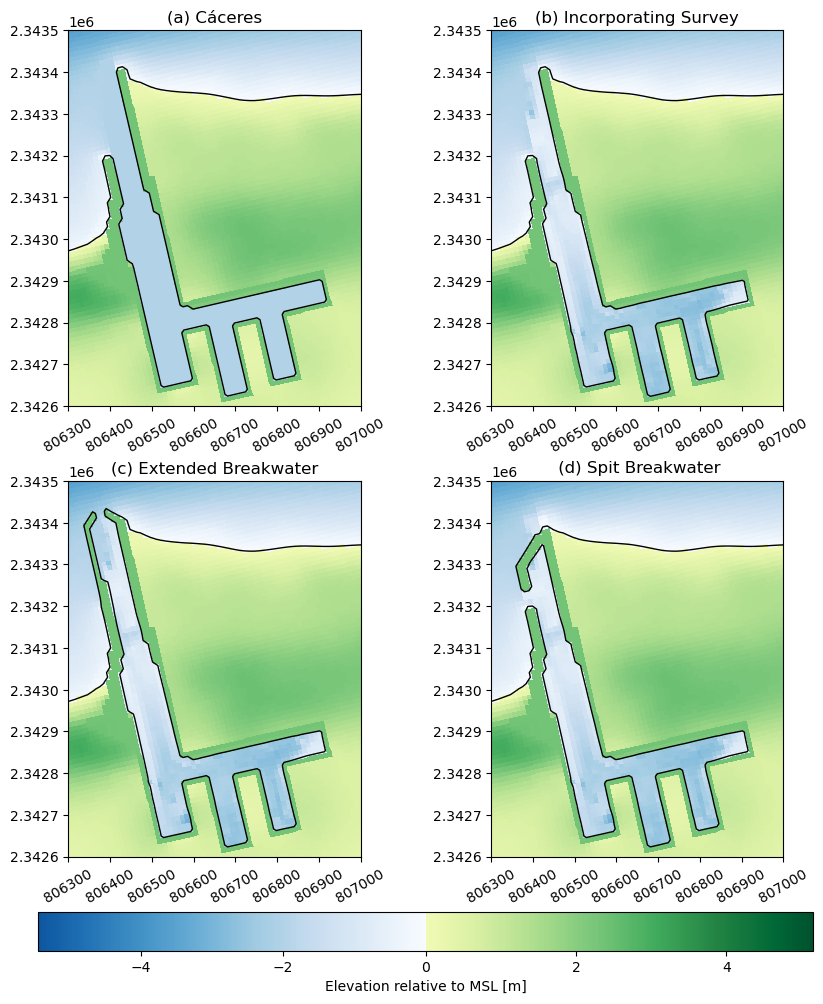

In [ ]:
grids = {}
for run in runs:
    with xr.open_dataset(map_files[run]) as ds:
        grids[run] = read_grid(ds)

# Blue below MSL, green above
bed_min = min(np.nanmin(bed) for _, _, bed in grids.values())
bed_max = max(np.nanmax(bed) for _, _, bed in grids.values())
norm = TwoSlopeNorm(vmin=bed_min, vcenter=0, vmax=bed_max)
bed_cmap = ListedColormap(np.vstack((
    plt.get_cmap('Blues_r')(np.linspace(0.15, 1, 128)),
    plt.get_cmap('YlGn')(np.linspace(0.15, 0.95, 128)),
)))

titles = ['(a) Cáceres', '(b) Incorporating Survey', '(c) Extended Breakwater', '(d) Spit Breakwater']

fig, axes = plt.subplots(2, 2, figsize=(10, 12))
for ax, run, title in zip(axes.flat, runs, titles):
    x, y, bed = grids[run]
    mesh = ax.pcolormesh(x, y, bed, cmap=bed_cmap, norm=norm)
    ax.contour(x, y, bed, levels=[0], colors='k', linewidths=1)
    ax.set_xlim(806300, 807000)
    ax.set_ylim(2342600, 2343500)
    ax.set_aspect('equal')
    ax.tick_params(axis='x', labelrotation=30)
    ax.set_title(title)

fig.colorbar(mesh, ax=axes, label='Elevation relative to MSL [m]', orientation='horizontal', fraction=0.046, pad=0.06)
plt.show()

# 10. Comparing the currents in the channel

Current speed and direction in the channel for all four alternatives at `compare_time`. The same figure is made twice: a 2x2 and a 1x4 layout.

In [ ]:
compare_time = '2023-05-09 03:00'

currents = {}
for run in runs:
    with xr.open_dataset(map_files[run]) as ds:
        currents[run] = read_currents(ds, nearest_time_index(ds, compare_time))

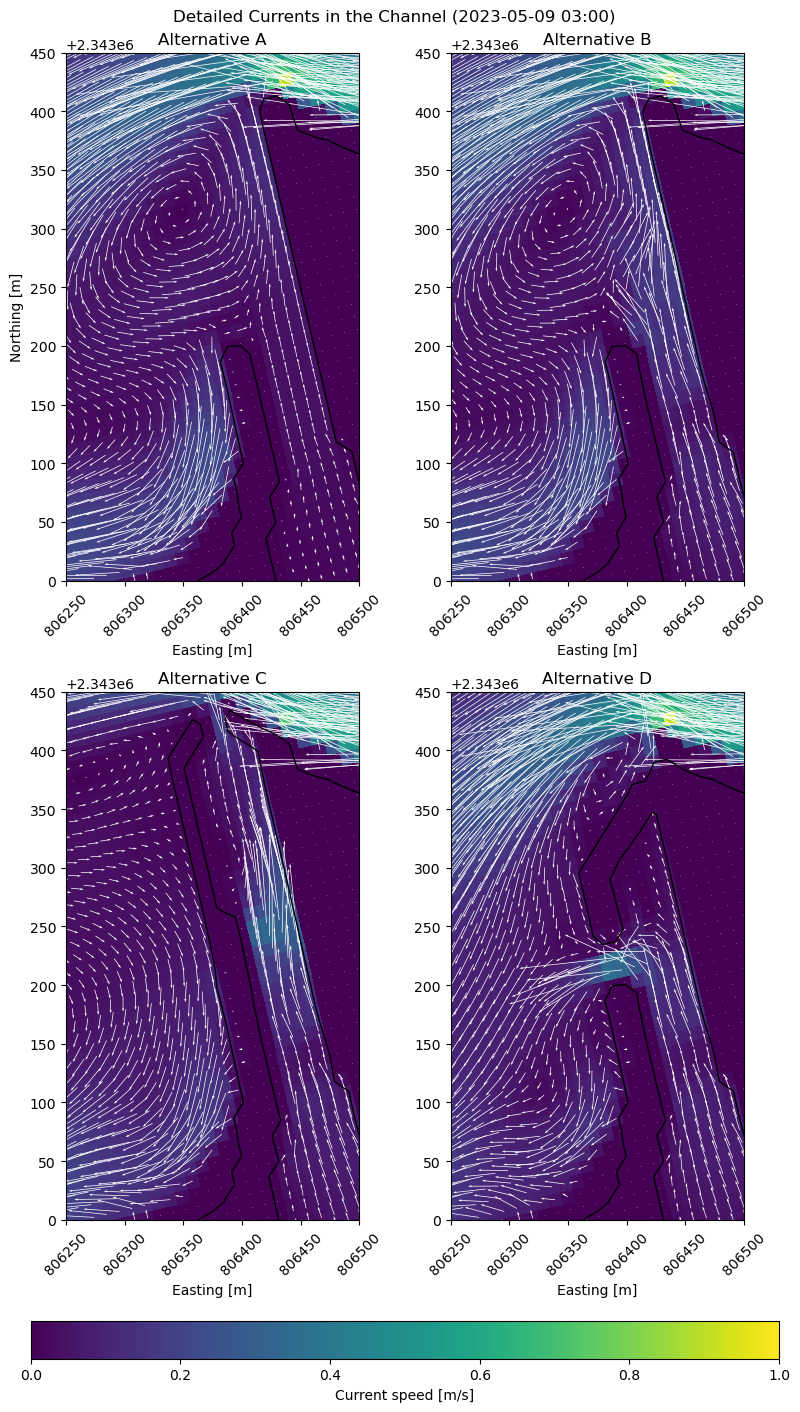

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(8, 14), layout='constrained')

for ax, (run, r) in zip(axes.flat, runs.items()):
    x, y, bed = grids[run]
    u, v = currents[run]
    mesh = ax.pcolormesh(x, y, np.hypot(u, v), cmap='viridis', vmin=0, vmax=1)
    ax.quiver(x, y, u, v, scale=1, color='w')
    channel_axes(ax, x, y, bed, f"Alternative {r['label']}", linewidth=1)

axes[0, 0].set_ylabel('Northing [m]')
fig.suptitle(f'Detailed Currents in the Channel ({compare_time})')
fig.colorbar(mesh, ax=axes, label='Current speed [m/s]', orientation='horizontal', fraction=0.046, pad=0.02)
plt.show()

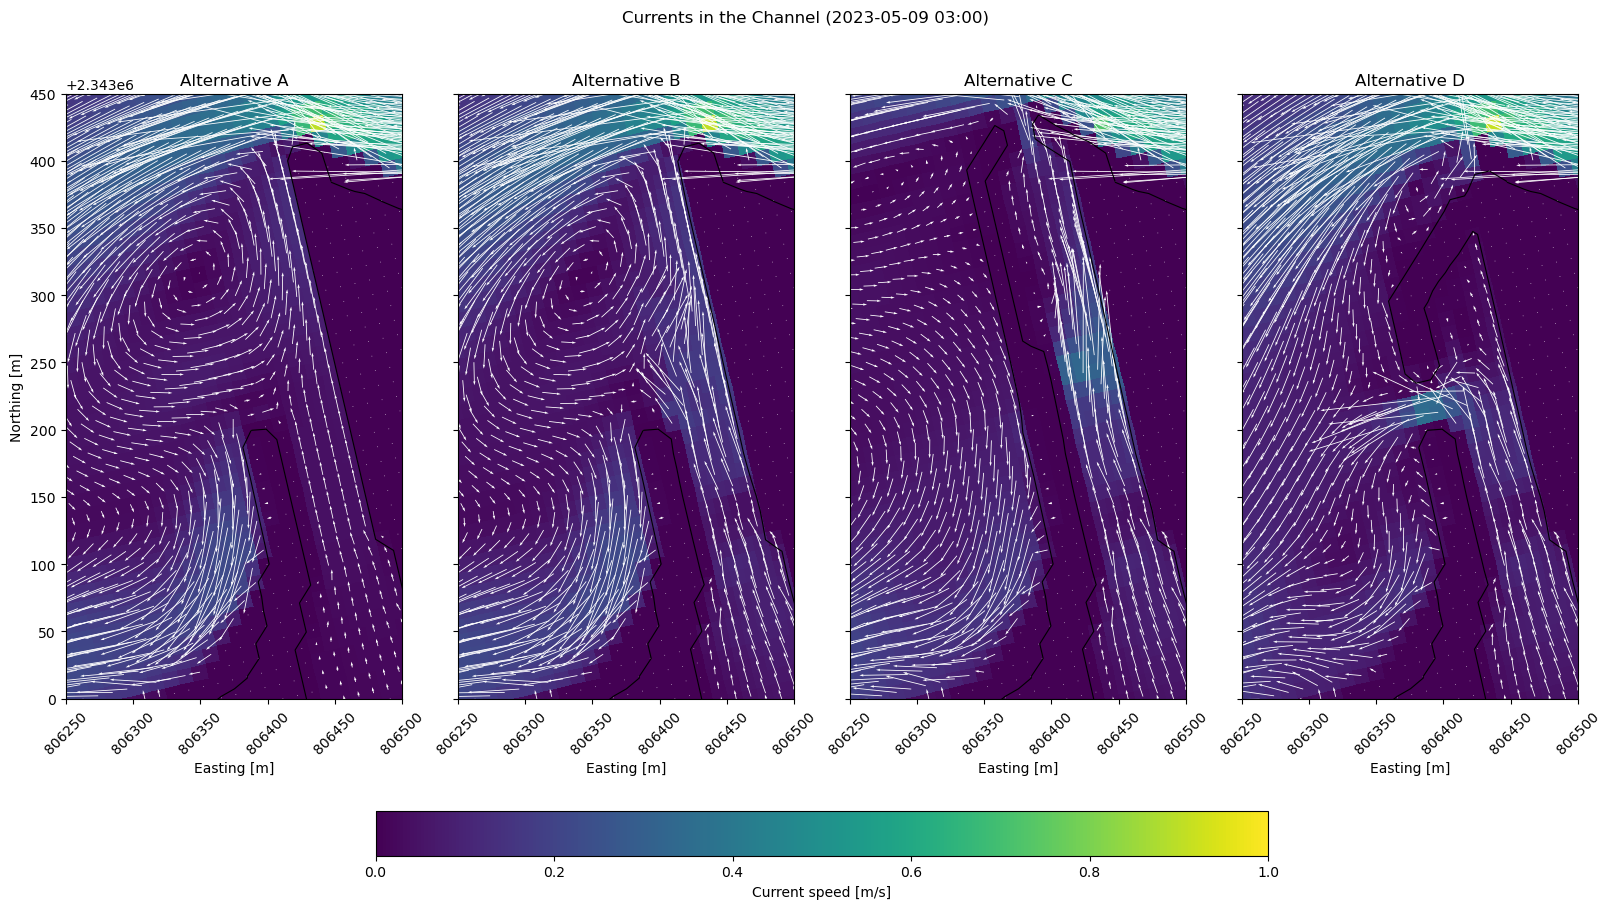

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 9), sharex=True, sharey=True, layout='constrained')

for ax, (run, r) in zip(axes, runs.items()):
    x, y, bed = grids[run]
    u, v = currents[run]
    mesh = ax.pcolormesh(x, y, np.hypot(u, v), cmap='viridis', vmin=0, vmax=1)
    ax.quiver(x, y, u, v, scale=1, color='w')
    channel_axes(ax, x, y, bed, f"Alternative {r['label']}")

axes[0].set_ylabel('Northing [m]')
fig.suptitle(f'Currents in the Channel ({compare_time})')
fig.colorbar(mesh, ax=axes, label='Current speed [m/s]', orientation='horizontal', fraction=0.067, pad=0.05)
plt.show()

# 11. Location of the stations and cross-sections

The station (first figure) and cross-section (second figure) used for each alternative in section 8.

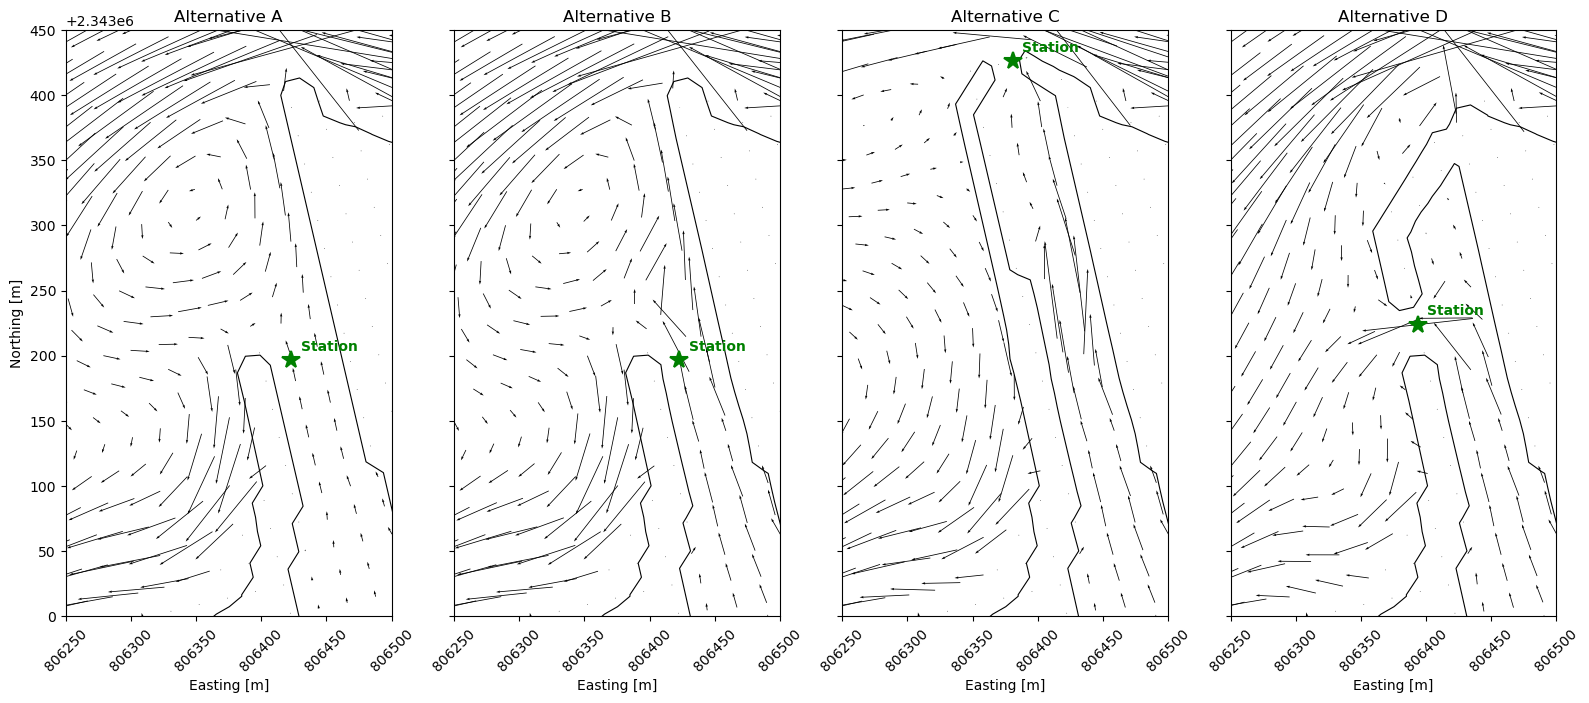

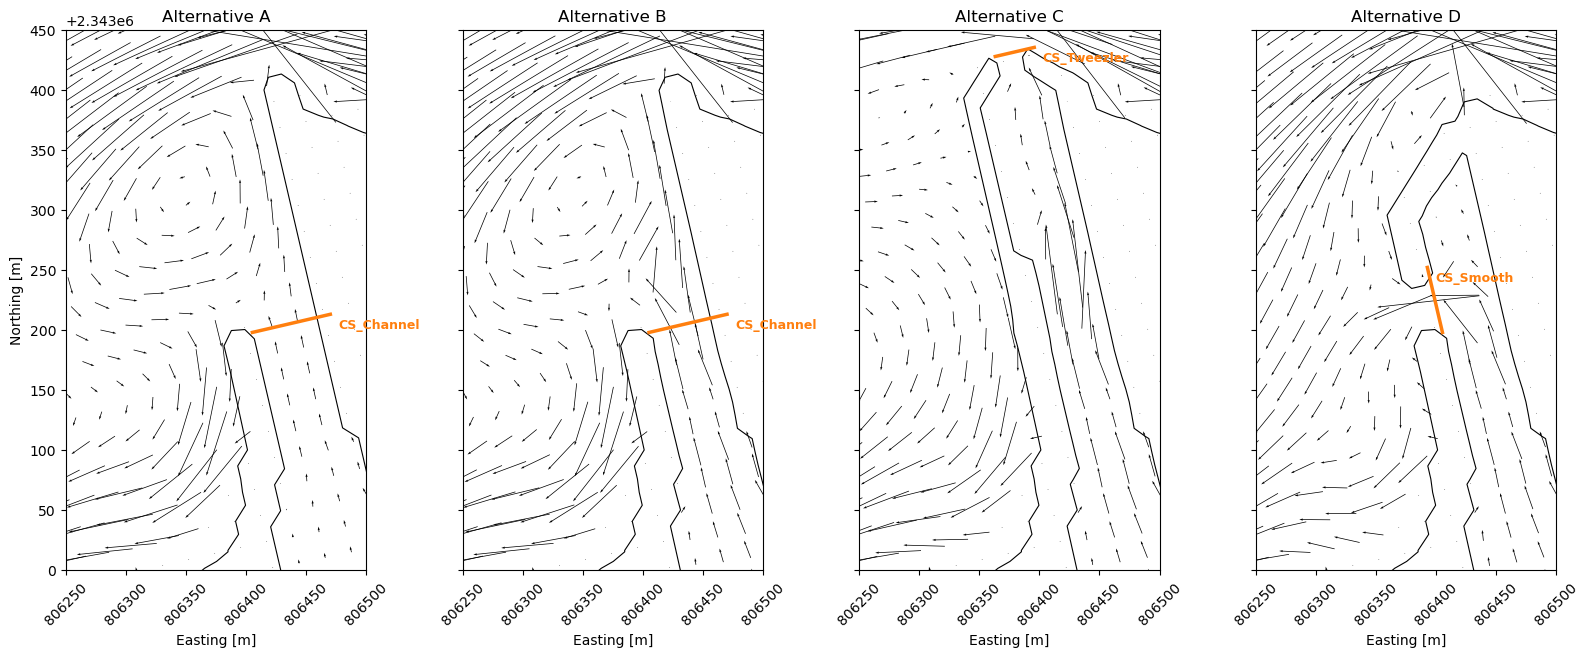

In [ ]:
for show in ['station', 'cross_section']:
    fig, axes = plt.subplots(1, 4, figsize=(16, 8), sharex=True, sharey=True)

    for ax, (run, r) in zip(axes, runs.items()):
        x, y, bed = grids[run]
        u, v = currents[run]
        quiver(ax, x, y, u, v, step=2, scale=1, color='black', pivot='middle')
        channel_axes(ax, x, y, bed, f"Alternative {r['label']}")

        if show == 'station':
            sx, sy = his_runs[run]['location']
            ax.plot(sx, sy, marker='*', color='green', markersize=13, markeredgewidth=1.5, linestyle='None')
            ax.annotate('Station', (sx, sy), xytext=(7, 7), textcoords='offset points',
                        color='green', fontsize=10, fontweight='bold')
        else:
            cs_x, cs_y = his_runs[run]['cross_section_xy']
            ax.plot(cs_x, cs_y, color='tab:orange', linewidth=2.5)
            ax.annotate(r['cross_section'], (cs_x[1], cs_y[1]), xytext=(6, -10), textcoords='offset points',
                        color='tab:orange', fontsize=9, fontweight='bold')

    axes[0].set_ylabel('Northing [m]')
    fig.tight_layout()
    plt.show()

# 12. Fall velocities of the sediment samples

Here we relate the flow velocities from the model to the sediment found in the harbour. The fall velocity $w_s$ is calculated following the Coastal Dynamics textbook (Bosboom & Stive, 2023).

First, the grain Reynolds number $Re = vD_{50}/\nu$ for a range of flow velocities $v$, using the $D_{50}$ of each sample from the sampling campaign and a kinematic viscosity $\nu = 10^{-6}$ m²/s for seawater.

The drag coefficient $C_D$ then follows from this figure (Bosboom & Stive, 2023):

![ReynoldstoDrag](Reynolds_to_Drag.png)

In [ ]:
samples = ['1a', '1b', '1c', '2a', '2b', '2c', '3a', '3b', '3c']
d50 = np.array([0.135, 0.024, 0.024, 0.825, 0.348, 0.941, 0.037, 0.193, 0.032]) * 1e-3  # [m]
velocities = [0.05, 0.1, 0.2, 0.3, 0.4]  # [m/s]
nu = 1e-6  # [m2/s]

rows = [f'v={v} m/s' for v in velocities]

Re = pd.DataFrame(np.outer(velocities, d50) / nu, index=rows, columns=samples)
display(Re)

,1a,1b,1c,2a,2b,2c,3a,3b,3c
v=0.05 m/s,6.75,1.2,1.2,41.25,17.4,47.05,1.85,9.65,1.6
v=0.1 m/s,13.50,2.4,2.4,82.50,34.8,94.10,3.70,19.30,3.2
v=0.2 m/s,27.00,4.8,4.8,165.00,69.6,188.20,7.40,38.60,6.4
v=0.3 m/s,40.50,7.2,7.2,247.50,104.4,282.30,11.10,57.90,9.6
v=0.4 m/s,54.00,9.6,9.6,330.00,139.2,376.40,14.80,77.20,12.8


Drag coefficients read from Figure 6.2 (Bosboom & Stive, 2023) using the Reynolds numbers above:

In [ ]:
CD = pd.DataFrame([[5.60, 22.00, 22.00, 1.80, 3.00, 1.60, 13.50, 4.30, 17.00],
                   [3.40, 13.50, 13.50, 1.25, 1.90, 1.15, 9.00, 2.80, 10.50],
                   [2.20, 7.50, 7.50, 0.85, 1.35, 0.80, 5.20, 1.80, 5.90],
                   [1.80, 5.30, 5.30, 0.72, 1.10, 0.68, 3.90, 1.50, 4.30],
                   [1.50, 4.30, 4.30, 0.62, 0.95, 0.60, 3.30, 1.30, 3.60]],
                  index=rows, columns=samples)
display(CD)

,1a,1b,1c,2a,2b,2c,3a,3b,3c
v=0.05 m/s,5.6,22.0,22.0,1.80,3.00,1.60,13.5,4.3,17.0
v=0.1 m/s,3.4,13.5,13.5,1.25,1.90,1.15,9.0,2.8,10.5
v=0.2 m/s,2.2,7.5,7.5,0.85,1.35,0.80,5.2,1.8,5.9
v=0.3 m/s,1.8,5.3,5.3,0.72,1.10,0.68,3.9,1.5,4.3
v=0.4 m/s,1.5,4.3,4.3,0.62,0.95,0.60,3.3,1.3,3.6


The fall velocity is then (Bosboom & Stive, 2023):

$$w_s = \sqrt{\frac{4(s - 1)gD}{3C_D}}$$

with $s = \rho_s/\rho_w$. Our geotechnical expert estimated the particle density at $\rho_s = 2720$ kg/m³.

In [ ]:
rho_s = 2720  # [kg/m3]
rho_w = 1025  # [kg/m3]
g = 9.81
s = rho_s / rho_w

ws = pd.DataFrame(np.sqrt(4 * (s - 1) * g * d50 / (3 * CD.values)), index=rows, columns=samples)
display(ws)

,1a,1b,1c,2a,2b,2c,3a,3b,3c
v=0.05 m/s,0.022835,0.004858,0.004858,0.099567,0.050091,0.112788,0.007699,0.031158,0.006381
v=0.1 m/s,0.029306,0.006201,0.006201,0.119481,0.062942,0.133037,0.009430,0.038612,0.008119
v=0.2 m/s,0.036432,0.008320,0.008320,0.144892,0.074671,0.159506,0.012406,0.048158,0.010831
v=0.3 m/s,0.040277,0.009897,0.009897,0.157430,0.082722,0.173008,0.014325,0.052755,0.012687
v=0.4 m/s,0.044121,0.010987,0.010987,0.169652,0.089013,0.184181,0.015573,0.056667,0.013866


Fall velocity as a fraction of the flow velocity, and everything together in one long table:

In [ ]:
pd.set_option('display.float_format', '{:.2f}'.format)

ws_fraction = ws.div(velocities, axis=0)
display(ws_fraction)

,1a,1b,1c,2a,2b,2c,3a,3b,3c
v=0.05 m/s,0.46,0.10,0.10,1.99,1.00,2.26,0.15,0.62,0.13
v=0.1 m/s,0.29,0.06,0.06,1.19,0.63,1.33,0.09,0.39,0.08
v=0.2 m/s,0.18,0.04,0.04,0.72,0.37,0.80,0.06,0.24,0.05
v=0.3 m/s,0.13,0.03,0.03,0.52,0.28,0.58,0.05,0.18,0.04
v=0.4 m/s,0.11,0.03,0.03,0.42,0.22,0.46,0.04,0.14,0.03


In [ ]:
n = len(samples)
combined_long = pd.DataFrame({
    'velocity': np.repeat(rows, n),
    'D50': np.tile(d50 * 1e3, len(velocities)),  # [mm]
    'sample': np.tile(samples, len(velocities)),
    'Re': Re.values.ravel(),
    'CD': CD.values.ravel(),
    'ws': ws.values.ravel(),
    'ws_fraction': ws_fraction.values.ravel(),
})
combined_long

index,velocity,D50,sample,Re,CD,ws,ws_fraction
0,v=0.05 m/s,0.14,1a,6.75,5.60,0.02,0.46
1,v=0.05 m/s,0.02,1b,1.20,22.00,0.00,0.10
2,v=0.05 m/s,0.02,1c,1.20,22.00,0.00,0.10
3,v=0.05 m/s,0.82,2a,41.25,1.80,0.10,1.99
4,v=0.05 m/s,0.35,2b,17.40,3.00,0.05,1.00
5,v=0.05 m/s,0.94,2c,47.05,1.60,0.11,2.26
6,v=0.05 m/s,0.04,3a,1.85,13.50,0.01,0.15
7,v=0.05 m/s,0.19,3b,9.65,4.30,0.03,0.62
8,v=0.05 m/s,0.03,3c,1.60,17.00,0.01,0.13
9,v=0.1 m/s,0.14,1a,13.50,3.40,0.03,0.29
